# The distribution of relationality → `figure_relationality.pdf`

The **relational-bias model's fitted `bias`**: how far the point a neuron measures object
direction from has slid from fixation (`bias = 0`, retinotopic) towards the pair's midpoint
(`bias = 1`, relational). One five-parameter model — baseline, amplitude, mean, width, bias —
fit to each neuron's 2-object trials, giving one interpretable number per neuron on a fixed
[0, 1] scale. See `relationality_lib.py` and `models_lib.RelationalBiasModel`, and
`prompts/MODEL_SUMMARY.pdf` §5 for how the metric works.

One panel per monkey, each normalised to a share of that monkey's neurons so the two are
comparable. Both ends carry an **atom**: outside [0, 1] the model is not identifiable
(`models_lib.BIAS_MAX` derives why), so a neuron whose optimum lies beyond a bound lands
exactly on it. Read the bars against 0 and 1 as counts of neurons sitting on a bound, not as a
bin's worth of spread.

The red dots are the example neurons `figure_example_neurons.ipynb` draws, read out of that
notebook's own `UNITS` list (commented-out lines excluded) so the two figures cannot drift apart.

In [1]:
import matplotlib.pyplot as plt

import common
common.set_style()
import data_lib as dl
import relationality_lib as rl
import plot_lib as pl

FIGSIZE = (5.6, 3.2)

OUTPUT = 'figure_relationality.pdf'
XLABEL = 'Relationality (r)'

# The metric's own model has to be in the list, or its fitted parameter is not in `summary`.
MODELS = ('future_field', 'relational_bias')

N_BINS = 15
LANDMARK_TOL = 0.15   # how close to a bound the table counts as "at" it
MARK_UNITS_NOTEBOOK = 'figure_example_neurons.ipynb'   # the example neurons to mark, read from there


In [2]:
summary = common.selected_fits(MODELS)

biases = rl.biases(summary)

mark_units = dl.units_from_notebook(MARK_UNITS_NOTEBOOK)
print(f'marking {len(mark_units)} example neurons: '
      + ', '.join(f'{s} {ses} unit {u}' for s, ses, u in mark_units))
for s in pl.levels(biases, 'subject'):
    v = biases[biases['subject'] == s]['bias']
    print(f'{dl.subject_title(s)}: {len(v)} neurons with a fitted bias, '
          f'median {v.median():.2f}, '
          f'{int((v <= 1e-9).sum())} at 0, {int((v >= 1 - 1e-9).sum())} at 1')

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
  restricted to 2 models (future_field, relational_bias); best_model recomputed within them
  dropped: basis_function, inhibition, normalization, priority_map, softmax, weighted_average
1339 of 3186 neurons enter the figure (42%)
1339 of 1339 neurons have a fitted bias
marking 5 example neurons: Perle 2022-06-16 unit 89, Perle 2022-06-09 unit 78, Perle 2022-06-11 unit 129, Perle 2022-06-10 unit 158, Perle 2022-06-11 unit 126
Monkey P: 998 neurons with a fitted bias, median 0.68, 128 at 0, 3 at 1
Monkey E: 341 neurons with a fitted bias, median 0.53, 57 at 0, 1 at 1


saved figure_relationality.pdf


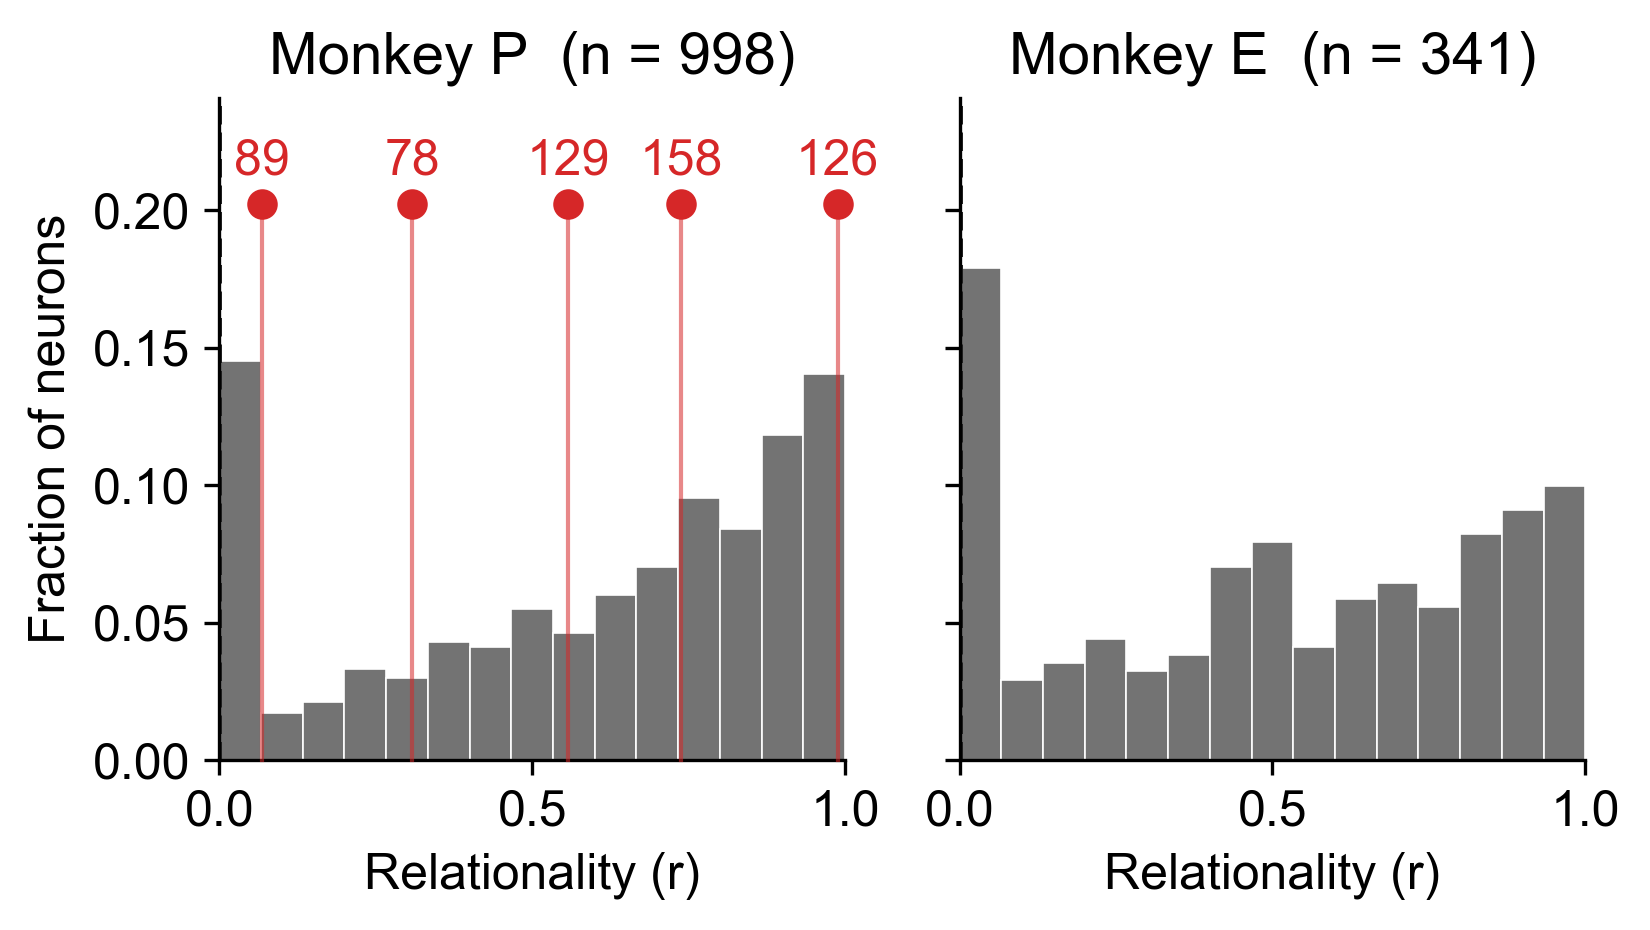

,n,median,frac_retinotopic,frac_future_field,frac_at_bound
subject,,,,,
Monkey P,998,0.676,0.168,0.280,0.131
Monkey E,341,0.527,0.211,0.208,0.170
All,1339,0.645,0.179,0.261,0.141


In [3]:
fig, _ = pl.plot_relationality_distribution(
    biases, figsize=FIGSIZE, bins=N_BINS, by_subject=True, normalize='fraction',
    bar_color='0.45', bar_edge_color='white', bar_edge_lw=0.4,
    landmark_color='0.15', landmark_lw=1.2, landmark_ls='--', landmark_labels=False,
    landmarks=('retinotopic',), xlabel=XLABEL, xticks=(0.0, 0.5, 1.0),
    show_n=True, sharey=True,
    mark_units=mark_units, mark_label_fmt='{unit}', mark_label_ha='center', mark_color='tab:red', mark_size=40,
    mark_fontsize=12, mark_rotation=0, mark_stem_lw=1.0, mark_stem_alpha=0.55,
    mark_base=0.84, mark_level_gap=0.13, mark_levels=2, mark_min_sep=0.12,
    mark_headroom=0.22)
common.save(fig, OUTPUT)
plt.show()

display(pl.relationality_table(biases, landmark_tol=LANDMARK_TOL).round(3))